# Dynamic ISFC on a movie dataset, with a BrainNet-style animation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/10_dynamic_isfc_animation.ipynb)

This notebook uses synchronized movie-viewing fMRI as an illustrative application of dynamic inter-subject functional correlation (ISFC). It fits HTFA to 12 adults from nilearn's `development_fmri` dataset, computes correlations between factor time courses across participants in sliding windows, and renders a brain-network animation. The BrainNet Viewer-style display places factor nodes inside a translucent brain surface and draws edges when windowed ISFC exceeds a threshold.

The dataset contains children and adults watching Pixar's short animated film *Partly Cloudy*; this example uses adults. Each run has 168 volumes acquired 2 seconds apart (TR), in 4 mm Montreal Neurological Institute (MNI) coordinates. Aligned sample `t` corresponds to the same movie moment across participants. That correspondence is required for this ISFC analysis; the same method can be used with other shared, time-aligned stimuli. HTFA fitting and the network renderer do not themselves require movie data.

Tutorial 06 covers within-subject static and dynamic connectivity and a matrix animation of ISFC on a small fit. This notebook is the ISFC workflow on its own: a larger fit, a null distribution from circularly shifted subjects, the global ISFC time course, and a 3D network movie.

**Requirements.** The plots use the `plot` and `brain3d` extras and the data download uses nilearn (`htfa[nilearn]`); htfa installs them the first time they are needed. The brain surface is BrainNet Viewer's `BrainMesh_Ch2withCerebellum.nv`; BrainNet Viewer is GPL-licensed, so htfa does not ship its meshes and downloads the BrainNet Viewer 1.43 archive from NITRC the first time a network is rendered (checked against a SHA-256 checksum and cached; see `htfa.brainnet.mesh_cache_dir`).

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [2]:
import base64
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
from IPython.display import HTML, display
from IPython.display import Image as DisplayImage

import htfa
from htfa import brainnet, timecourse

plt = htfa.require("matplotlib.pyplot")
T0 = time.perf_counter()

# Downloads are cached outside the repository.
CACHE = Path.home() / ".cache" / "htfa" / "tutorials"
CACHE.mkdir(parents=True, exist_ok=True)
# Figures embedded in the documentation (./figures outside the docs).
DOCS = Path.cwd().parent / "_static"
STATIC = DOCS / "tutorials" if DOCS.is_dir() else Path("figures")
STATIC.mkdir(parents=True, exist_ok=True)

## 1. Loading and preprocessing

`htfa.datasets.fetch_development_fmri(n_subjects=12)` downloads the first 12 adults (only runs that are not yet in nilearn's data directory) and applies the following preprocessing for this example:

- it masks each run with the MNI152 brain mask resampled to the data grid, minus voxels whose mean intensity is below 10% of the median (outside that subject's brain) and voxels that are nearly constant over any quarter of the run;
- it removes a linear trend and regresses out the dataset's reduced confound set (motion, CompCor, CSF and white-matter signals).

`HTFA` then z-scores each voxel (`standardize='auto'`). Masks differ slightly between subjects; HTFA fits each subject at its own voxel coordinates, so the voxel counts need not match.

In [3]:
ds = htfa.datasets.fetch_development_fmri(n_subjects=12)
ids, Xs, Rs = ds.subject_ids, ds.data, ds.coords
T = Xs[0].shape[1]
TR = 2.0
print("adults:", len(ids), f"({ids[0]} to {ids[-1]})")
print("voxels per subject:", [X.shape[0] for X in Xs])
print("samples per subject:", sorted({X.shape[1] for X in Xs}))

adults: 12 (sub-pixar123 to sub-pixar134)
voxels per subject: [25079, 23726, 26739, 27257, 27038, 27918, 27358, 27264, 27525, 27986, 27739, 27186]
samples per subject: [168]


## 2. Fitting HTFA

`K = 50` factors. Following the *Performance* page, each iteration solves for the centers and widths on a random subset of 3000 voxels (`max_voxels=3000`; all 168 samples are used), and `init='ncorr'` starts each subject from a single correlation-based start instead of also running the K-means start.

By default (`REFIT = False`) the next cell downloads a saved copy of this fit with `htfa.datasets.fetch_tutorial_fit` from the `tutorial-data-v1` data release of the htfa repository, checks its SHA-256 and loads it with `np.load(..., allow_pickle=False)`; the printed lines describe the fitting settings. `REFIT = True` fits HTFA from scratch instead, with one parallel job per CPU (`n_jobs=os.cpu_count()`); that result is not cached.

In [4]:
# Fit from scratch (True), or download the saved fit made with these settings
# (False, the default; 0.8 MB).
REFIT = False
NAME = "development_fmri_12adults_K50"

K = 50
params = dict(K=K, max_voxels=3000, max_global_iter=10, init="ncorr", random_state=0)
if REFIT:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = htfa.HTFA(**params, n_jobs=os.cpu_count()).fit(Xs, Rs)
    fit = dict(
        weights=np.stack(model.weights_),
        global_centers=model.global_centers_,
        global_widths=model.global_widths_,
        n_iter=model.n_iter_,
        converged=model.converged_,
        fit_seconds=time.perf_counter() - t0,
        warnings=[f"{w.category.__name__}: {w.message}" for w in caught],
    )
else:
    fit = htfa.datasets.fetch_tutorial_fit(NAME)
    saved = json.loads(str(fit["settings"]))
    assert {k: saved[k] for k in params} == params, saved
    assert list(fit["subject_ids"]) == ids, fit["subject_ids"]
    print(f"saved fit: htfa.datasets.fetch_tutorial_fit({NAME!r}), SHA-256 checked")
    print("settings:", fit["settings"])
weights = list(fit["weights"])
centers, widths = fit["global_centers"], fit["global_widths"]
if REFIT:
    print(f"fit time: {float(fit['fit_seconds']):.0f} s")
print("global iterations:", int(fit["n_iter"]), "| converged:", bool(fit["converged"]))
# Count the warnings by category and the start of their message.
kinds = {}
for msg in filter(None, map(str, fit["warnings"])):
    head = msg.split(" in ")[0].split(";")[0][:90]
    kinds[head] = kinds.get(head, 0) + 1
for head, n in sorted(kinds.items()):
    print(f"warning x{n}: {head}")
print("weights:", len(weights), "subjects x", weights[0].shape)

saved fit: htfa.datasets.fetch_tutorial_fit('development_fmri_12adults_K50'), SHA-256 checked
settings: {"K": 50, "init": "ncorr", "random_state": 0, "n_jobs": 12, "max_voxels": 3000, "max_global_iter": 10}
global iterations: 10 | converged: False
warning x1: ConvergenceWarning: HTFA did not converge
weights: 12 subjects x (50, 168)


The fit stops at `max_global_iter=10` before the template change falls below `threshold=1e-3`, so HTFA issues a `ConvergenceWarning`. With voxel subsampling the change between iterations has a noise floor (see *Performance*, "Subsampling and stopping"); the factors are used as they are.

## 3. Static ISFC

`htfa.isfc(weights)` correlates each subject's factor time courses with the mean of the other subjects' time courses (factor *i* of one subject against factor *j* of the rest), symmetrizes, and averages over subjects in Fisher-z space. It emphasizes activity shared across subjects during the movie; shared artifacts can also contribute, so ISFC is not by itself evidence of a stimulus-specific cause. The diagonal is each factor's inter-subject correlation (ISC).

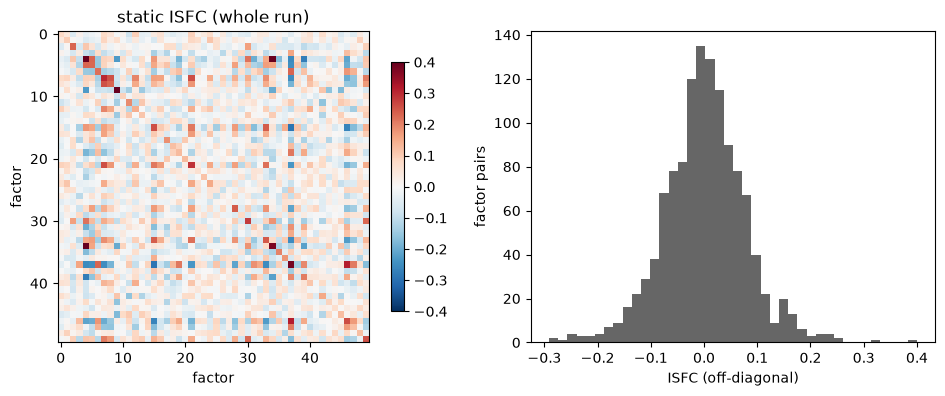

ISC (diagonal): median 0.127, range 0.0058 to 0.486
off-diagonal: mean 0.001, range -0.291 to 0.400


In [5]:
C = htfa.isfc(weights)
iu = np.triu_indices(K, 1)
isc = np.diag(C)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(C, vmin=-0.4, vmax=0.4, cmap="RdBu_r")
ax[0].set(title="static ISFC (whole run)", xlabel="factor", ylabel="factor")
fig.colorbar(im, ax=ax[0], shrink=0.8)
ax[1].hist(C[iu], bins=40, color="0.4")
ax[1].set(xlabel="ISFC (off-diagonal)", ylabel="factor pairs")
plt.tight_layout()
plt.show()
print(
    f"ISC (diagonal): median {np.median(isc):.3f}, "
    f"range {isc.min():.4f} to {isc.max():.3f}"
)
off = C[iu]
print(f"off-diagonal: mean {off.mean():.3f}, range {off.min():.3f} to {off.max():.3f}")

## 4. Sliding-window ISFC

`htfa.isfc(weights, window=w)` repeats the computation within each window of `w` consecutive samples, giving a `(T - w + 1, K, K)` array. The window is a trade-off: a correlation over `w` samples has a sampling standard deviation of about `1 / sqrt(w - 3)` in Fisher-z units for independent samples (0.24 for `w = 20`), and a longer window averages over more of the movie. Here `w = 20` samples (40 s); each window is labelled by its centre time.

In [6]:
w = 20
D = htfa.isfc(weights, window=w)
t_mid = (np.arange(len(D)) + (w - 1) / 2) * TR  # window centre in seconds
print("sliding-window ISFC:", D.shape)
print(f"window centres: {t_mid[0]:.0f} s to {t_mid[-1]:.0f} s")

sliding-window ISFC: (149, 50, 50)
window centres: 19 s to 315 s


### A null from circularly shifted subjects

To see how large windowed ISFC values get without aligned movie times, each subject's weights are circularly shifted by its own random offset (at least one window from zero), which keeps each time course intact but misaligns the subjects in time; the sliding-window ISFC is then recomputed. 100 such shifts give a null distribution for every window.

In [7]:
rng = np.random.default_rng(0)
n_null = 100
t0 = time.perf_counter()
null_global = np.empty((n_null, len(D)))
null_edges = []
for k in range(n_null):
    shifted = [np.roll(W, rng.integers(w, T - w), axis=1) for W in weights]
    Dn = htfa.isfc(shifted, window=w)
    null_global[k] = timecourse.global_connectivity(Dn)
    null_edges.append(Dn[:, iu[0], iu[1]])
null_edges = np.concatenate(null_edges, axis=None)
print(f"{n_null} shifted copies in {time.perf_counter() - t0:.0f} s")

100 shifted copies in 15 s


## 5. Choosing the edge threshold

An edge is drawn when `|ISFC| > threshold`. A fixed threshold such as 0.25 would show a different share of the network depending on the fit and the window length, so the threshold is taken from the null: the 99.9th percentile of the absolute off-diagonal values of all shifted copies. Edges above it are larger than all but 0.1% of the edge values seen when the subjects are misaligned. `htfa.timecourse.edge_count` counts the drawn edges in each frame.

In [8]:
threshold = float(np.percentile(np.abs(null_edges), 99.9))
n_edges = timecourse.edge_count(D, threshold=threshold)
null_rate = np.mean(np.abs(null_edges) > threshold)
E_all = D[:, iu[0], iu[1]]
print(f"threshold: |ISFC| > {threshold:.3f}")
print(
    f"edges per frame: median {np.median(n_edges):.0f}, range {n_edges.min():.0f} "
    f"to {n_edges.max():.0f} (of {len(iu[0])} pairs)"
)
print(f"expected under the null: {null_rate * len(iu[0]):.1f} edges per frame")
print(f"frames with no edge: {(n_edges == 0).sum()}")
print(
    f"drawn edges that are negative: {(E_all < -threshold).sum()} "
    f"of {(np.abs(E_all) > threshold).sum()}"
)

threshold: |ISFC| > 0.257
edges per frame: median 51, range 3 to 177 (of 1225 pairs)
expected under the null: 1.2 edges per frame
frames with no edge: 0
drawn edges that are negative: 4175 of 8750


## 6. ISFC over the movie

The top panel is `htfa.timecourse.global_connectivity`: the mean over the upper triangle of each frame, including the diagonal (the factors' ISC). Positive and negative edges cancel in this mean. `plot_timecourse` draws it with a centered 5-window moving average (`smooth=5`); the gray band is the 2.5th to 97.5th percentile of the shifted copies at each window, smoothed the same way. The bottom panel is the number of edges above the threshold in each frame (unsmoothed), with the number expected under the null as a dashed line.

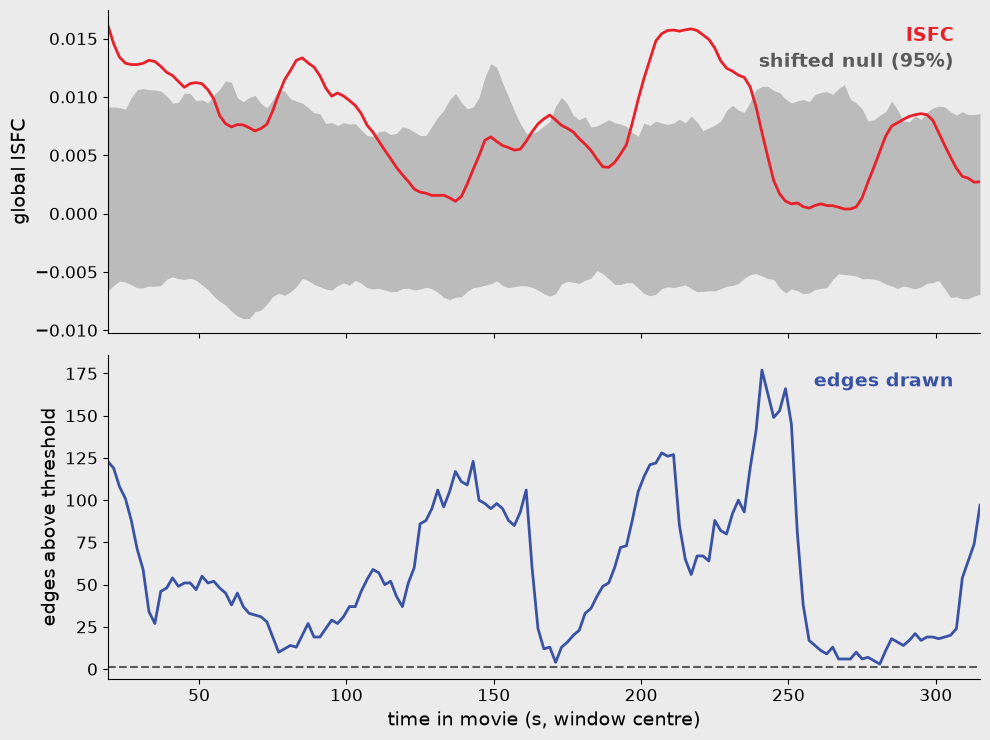

smoothed global ISFC: 0.000 to 0.016
peak at window centre 19 s (0.016); lowest at 269 s (0.000)
null band (smoothed): -0.009 to 0.013
windows above the 97.5th null percentile: 63 of 149, window centres 19-53 s, 79-109 s, 163-169 s, 197-237 s, 289-295 s
most edges: 177 at 241 s; fewest: 3 at 281 s


In [9]:
g = timecourse.global_connectivity(D)
g_s = timecourse.moving_average(g, 5)
lo, hi = np.percentile(timecourse.moving_average(null_global, 5), [2.5, 97.5], axis=0)
bg = timecourse.SLIDE_COLORS["background"]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, facecolor=bg)
htfa.plot_timecourse(
    {"ISFC": g}, x=t_mid, smooth=5, ylabel="global ISFC", fontsize=14, ax=ax
)
ax.fill_between(t_mid, lo, hi, color="0.55", alpha=0.5, lw=0, zorder=0)
ax.text(
    0.97,
    0.87,
    "shifted null (95%)",
    color="0.35",
    fontweight="bold",
    fontsize=14,
    transform=ax.transAxes,
    ha="right",
    va="top",
)
htfa.plot_timecourse(
    {"edges drawn": n_edges},
    x=t_mid,
    colors={"edges drawn": timecourse.SLIDE_COLORS["blue"]},
    xlabel="time in movie (s, window centre)",
    ylabel="edges above threshold",
    fontsize=14,
    ax=ax2,
)
ax2.axhline(null_rate * len(iu[0]), color="0.35", ls="--", lw=1.5)
plt.show()
peak, trough = int(np.argmax(g_s)), int(np.argmin(g_s))
above = g_s > hi
# Runs of consecutive windows above the null band.
edges_of_runs = np.flatnonzero(np.diff(np.r_[0, above.astype(int), 0]))
runs = [(t_mid[a], t_mid[b - 1]) for a, b in edges_of_runs.reshape(-1, 2)]
print(f"smoothed global ISFC: {g_s.min():.3f} to {g_s.max():.3f}")
print(
    f"peak at window centre {t_mid[peak]:.0f} s ({g_s[peak]:.3f}); "
    f"lowest at {t_mid[trough]:.0f} s ({g_s[trough]:.3f})"
)
print(f"null band (smoothed): {lo.min():.3f} to {hi.max():.3f}")
print(
    f"windows above the 97.5th null percentile: {above.sum()} of {len(D)}, "
    "window centres " + ", ".join(f"{a:.0f}-{b:.0f} s" for a, b in runs)
)
print(
    f"most edges: {n_edges.max():.0f} at {t_mid[np.argmax(n_edges)]:.0f} s; "
    f"fewest: {n_edges.min():.0f} at {t_mid[np.argmin(n_edges)]:.0f} s"
)

## 7. A still frame

`htfa.plot_network` renders the template factors as gray spheres sized by their widths, and the edges above the threshold as tubes, red for positive and blue for negative ISFC. In BrainNet Viewer's "intensity" edge style the tube diameter is the edge value in mm; ISFC values here are below 0.5, which gives tubes too thin to see at these image sizes, so the matrices passed to the renderer are multiplied by `edge_scale = 5` (diameter `5 |ISFC|` mm) and the threshold with them. Which edges are drawn does not change.

Below, the window with the highest smoothed global ISFC, from the left (BrainNet's default lateral view) and from above.

Nodes are drawn at their in-brain centroid by default (`snap=True`): the RBF-weighted centroid of the in-brain voxels, with the weighted spread as the width. For an `HTFAResults`, `res.display_nodes()` returns the drawn centers and widths; here the fit comes from the cache, so `htfa.brainnet.effective_nodes` with all subjects' voxels as the mask gives the same numbers.

In [10]:
# All subjects' voxels: the mask that res.display_nodes() uses for the template.
mask = np.unique(np.vstack(Rs), axis=0)
shown, shown_widths, info = brainnet.effective_nodes(centers, widths, mask)
d = info["distance"]
print(f"fitted to drawn center: median {np.median(d):.1f} mm, max {d.max():.1f} mm")
print(f"centroids outside the mask, moved onto it: {info['snapped'].sum()} of {K}")

fitted to drawn center: median 8.5 mm, max 27.1 mm
centroids outside the mask, moved onto it: 0 of 50


123 edges; image 1234 x 707 pixels


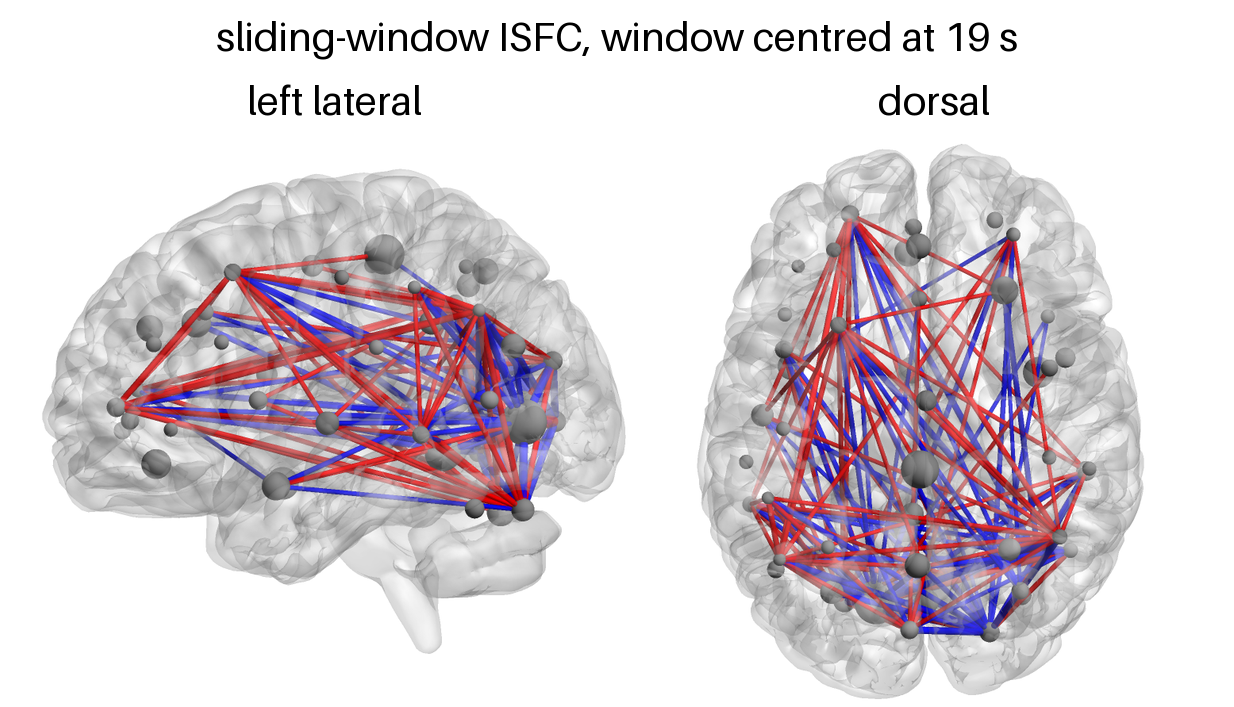

In [11]:
edge_scale = 5
style = dict(threshold=edge_scale * threshold, size=(1200, 750), mask=mask)
views = ("lateral", "dorsal")
still = {
    v: htfa.plot_network(centers, edge_scale * D[peak], widths=widths, view=v, **style)
    for v in views
}
panel = brainnet.montage(
    [[still["lateral"], still["dorsal"]]],
    row_labels=[""],
    col_labels=["left lateral", "dorsal"],
    title=f"sliding-window ISFC, window centred at {t_mid[peak]:.0f} s",
    cell_width=600,
    out=STATIC / "10_isfc_peak_frame.png",
)
print(f"{n_edges[peak]:.0f} edges; image {panel.size[0]} x {panel.size[1]} pixels")
display(
    DisplayImage(data=(STATIC / "10_isfc_peak_frame.png").read_bytes(), format="png")
)

## 8. A montage of time points

`htfa.brainnet.montage` arranges frames in a grid. Columns: the first window, the window with the highest smoothed global ISFC, the one with the lowest, and the last window; rows: the two views.

first: window centre 19 s, 123 edges
peak: window centre 19 s, 123 edges
lowest: window centre 269 s, 6 edges
last: window centre 315 s, 97 edges


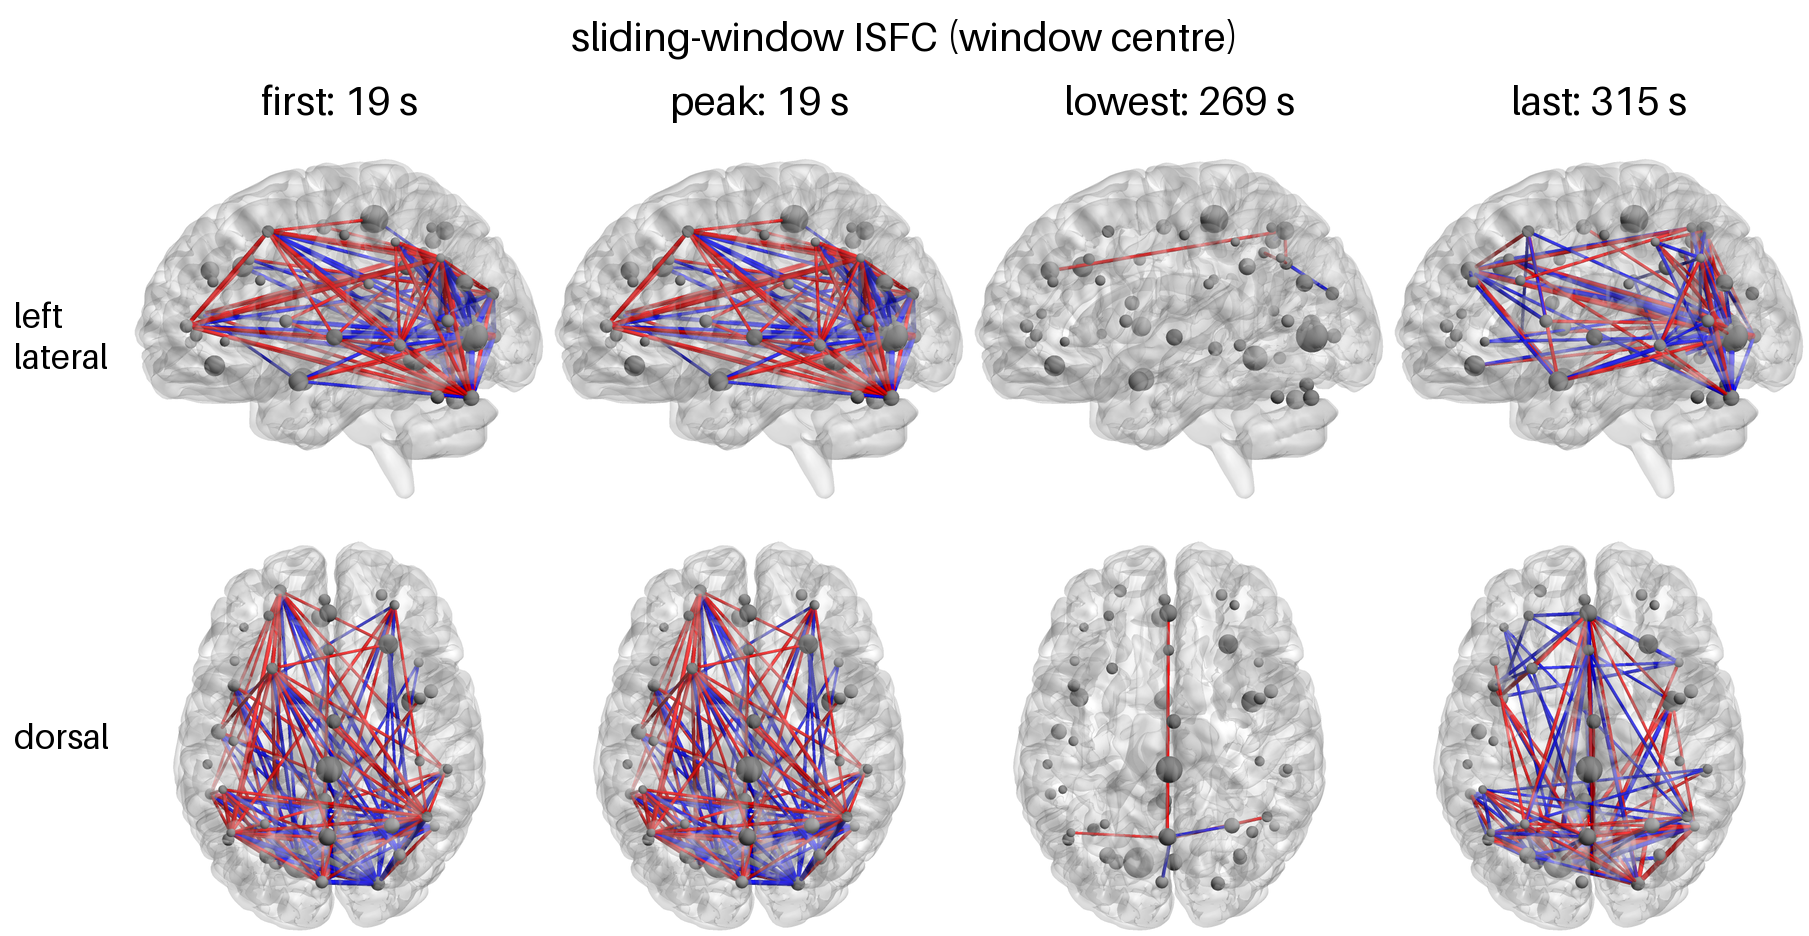

In [12]:
picks = {"first": 0, "peak": peak, "lowest": trough, "last": len(D) - 1}
grid = [
    [
        htfa.plot_network(centers, edge_scale * D[i], widths=widths, view=v, **style)
        for i in picks.values()
    ]
    for v in views
]
brainnet.montage(
    grid,
    row_labels=["left\nlateral", "dorsal"],
    col_labels=[f"{name}: {t_mid[i]:.0f} s" for name, i in picks.items()],
    title="sliding-window ISFC (window centre)",
    cell_width=420,
    out=STATIC / "10_isfc_montage.png",
)
for name, i in picks.items():
    print(f"{name}: window centre {t_mid[i]:.0f} s, {n_edges[i]:.0f} edges")
display(DisplayImage(data=(STATIC / "10_isfc_montage.png").read_bytes(), format="png"))

## 9. The animation

`htfa.animate_network` renders a `(T, K, K)` series with the camera, mesh, nodes and threshold fixed across frames, and writes an mp4 or a looping GIF. To keep the GIF small enough for the documentation, it shows every second window from the dorsal view at 640 x 400 pixels, 5 frames per second; each caption gives the window's span in the movie, its global ISFC and its number of edges. For a full-resolution movie of all windows, pass `D` and `out="movie.mp4"`.

frames: 75 | GIF size: 1.41 MB



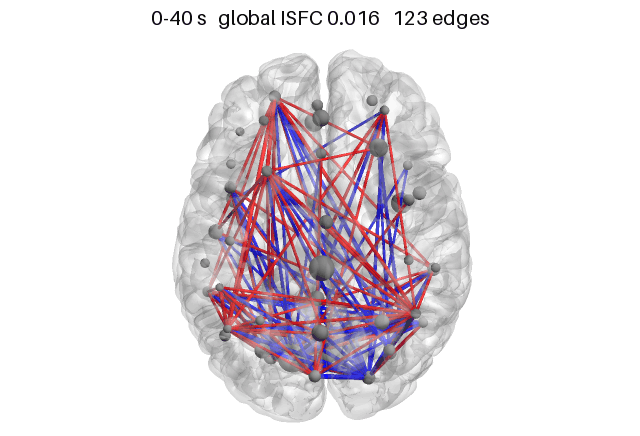

In [13]:
frames = np.arange(0, len(D), 2)
captions = [
    f"{i * TR:.0f}-{(i + w) * TR:.0f} s   "
    f"global ISFC {g[i]:.3f}   {n_edges[i]:.0f} edges"
    for i in frames
]
gif = htfa.animate_network(
    centers,
    edge_scale * D[frames],
    STATIC / "10_isfc_animation.gif",
    widths=widths,
    mask=mask,
    fps=5,
    captions=captions,
    view="dorsal",
    threshold=edge_scale * threshold,
    size=(640, 400),
)
print("frames:", len(frames), f"| GIF size: {gif.stat().st_size / 1e6:.2f} MB")
encoded_gif = base64.b64encode(gif.read_bytes()).decode("ascii")
display(
    HTML(
        f'<img src="data:image/gif;base64,{encoded_gif}" '
        'alt="Sliding-window ISFC animation">'
    )
)

## 10. Summary of the numbers

The statements below are computed from the arrays above.

In [14]:
print(
    f"global ISFC (smoothed) peaks in the window centred at {t_mid[peak]:.0f} s "
    f"(samples covering {t_mid[peak] - (w - 1) / 2 * TR:.0f}-"
    f"{t_mid[peak] + (w + 1) / 2 * TR:.0f} s of the movie) "
    f"and is lowest at {t_mid[trough]:.0f} s"
)
print(
    f"{above.sum()} of {len(D)} windows lie above the 97.5th percentile of the "
    f"shifted copies (2.5% of {len(D)} windows is {0.025 * len(D):.1f}; neighbouring "
    f"windows share {w - 1} of {w} samples, so they are not independent)"
)
print(
    f"edges drawn per frame range from {n_edges.min():.0f} to {n_edges.max():.0f}; "
    f"the null predicts {null_rate * len(iu[0]):.1f}"
)
r = np.corrcoef(g, n_edges)[0, 1]
print(f"correlation between global ISFC and the number of drawn edges: {r:.2f}")
share_neg = (E_all < -threshold).sum() / (np.abs(E_all) > threshold).sum()
print(f"negative edges among all drawn edges: {share_neg:.0%}")
print(f"total notebook run time: {time.perf_counter() - T0:.0f} s")

global ISFC (smoothed) peaks in the window centred at 19 s (samples covering 0-40 s of the movie) and is lowest at 269 s
63 of 149 windows lie above the 97.5th percentile of the shifted copies (2.5% of 149 windows is 3.7; neighbouring windows share 19 of 20 samples, so they are not independent)
edges drawn per frame range from 3 to 177; the null predicts 1.2
correlation between global ISFC and the number of drawn edges: 0.06
negative edges among all drawn edges: 48%
total notebook run time: 26 s


Read the global ISFC and edge-count curves together: positive and negative edges can cancel in the global mean, so a window with many strong edges need not have high global ISFC. The printed summaries give the peak/minimum windows and signed-edge proportions for the loaded fit. These are descriptive results for one K=50 fit of 12 subjects and one null of 100 shifts; check the reported convergence status and do not treat individual excursions beyond the plotted band as a multiplicity-corrected significance test.